## Import Libraries

In [3]:
import keras
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

## Data Collection and Understanding

In [4]:
(X_train,y_train),(X_test,y_test) = keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1808s 11us/step


In [6]:
print(X_train.shape,y_train.shape)

(50000, 32, 32, 3) (50000, 1)


In [7]:
print(X_test.shape,y_test.shape)

(10000, 32, 32, 3) (10000, 1)


In [29]:
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3) 
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

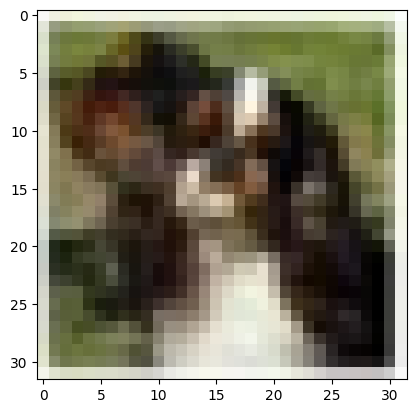

In [10]:
plt.imshow(X_train[500])

## Data  Preparation

#### Normalization

In [35]:
X_train =  X_train/255.0

In [36]:
X_test =  X_test/255.0

In [37]:
X_train.max(),X_train.min()

(np.float64(1.0), np.float64(0.0))

## Model Building, training,testing and evaluation

In [38]:
from keras import Sequential
from keras.layers import Flatten,Dense

In [39]:
model = Sequential()

model.add(layer = Flatten())
model.add(Dense(units= 100, activation= "relu"))
model.add(Dense(units= 10, activation= "softmax"))

In [42]:
model.compile(optimizer='adam',loss="sparse_categorical_crossentropy",metrics=["Accuracy"])

In [44]:
model.fit(x=X_train,y=y_train, batch_size=30,epochs=10,validation_split=0.2)

Epoch 1/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - Accuracy: 0.4326 - loss: 1.5834 - val_Accuracy: 0.4228 - val_loss: 1.6193
Epoch 2/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - Accuracy: 0.4343 - loss: 1.5790 - val_Accuracy: 0.4300 - val_loss: 1.6158
Epoch 3/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - Accuracy: 0.4400 - loss: 1.5696 - val_Accuracy: 0.4250 - val_loss: 1.6224
Epoch 4/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - Accuracy: 0.4403 - loss: 1.5635 - val_Accuracy: 0.4348 - val_loss: 1.6064
Epoch 5/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - Accuracy: 0.4437 - loss: 1.5559 - val_Accuracy: 0.4314 - val_loss: 1.6165
Epoch 6/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - Accuracy: 0.4423 - loss: 1.5545 - val_Accuracy: 0.4179 - val_loss: 1.6284
Epoch 7/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - Accuracy: 0.4475 - loss: 1.5452 - val_Accuracy: 0.4283 - val_loss: 1.6035
Epoch 8/10
1334/1334 ━━━━━━━━━━━━━━━━━━━━ 16s 12ms/step - Accuracy: 0.4507 - 

In [45]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


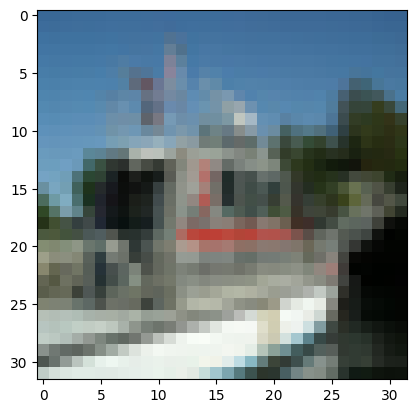

In [47]:
plt.imshow(X_test[600])

In [48]:
np.argmax(y_pred[600])

np.int64(0)

In [49]:
model.save("colored_image.h5")

## Lets uploading an image and predicting the correct answer

In [67]:
from PIL import Image

img_path = r"C:\Users\Madhumitha B\Downloads\frog.jpg"

my_image = Image.open(img_path).resize((32,32))
my_image  = np.array(my_image)

In [68]:
from keras.models import load_model
Load_model = load_model("colored_image.h5")

In [69]:
def predict_image(my_image):
    my_image = my_image/255.0
    my_image = np.expand_dims(my_image, axis =0)
    prediction = Load_model.predict(my_image)
    return np.argmax(prediction)

In [70]:
predict_image(my_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step


np.int64(6)